# Collections and prefix sums

Keep the balance after every signed change, including a negative change and a zero.

After processing position i, the state equals the sum of the first i changes. That invariant gives a proof by induction and a simple reference implementation. A one-pass algorithm costs linear time. Computing each prefix separately costs quadratic time but is convenient for checking six short observations.

A slice borrows the vector. scan retains state inside a closure and collect materialises the returned values.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.rs`

```rust
fn balances(changes: &[i32]) -> Vec<i32> {
    changes.iter().scan(0, |state, &change| {
        *state += change;
        Some(*state)
    }).collect()
}
fn main() {
    let changes = vec![3, -1, 4, -2, 0, 2];
    for total in balances(&changes) { print!("{total} "); }
    assert_eq!(changes.len(), 6);
}
```

## Execute the native listing

A slice borrows the vector. scan retains state inside a closure and collect materialises the returned values. Read the type and ownership information at the function boundary. A borrowed slice permits access to existing storage while the owner retains responsibility for its lifetime.

In [2]:
x = [3, -1, 4, -2, 0, 2]
expected = np.asarray([sum(x[:i]) for i in range(1, len(x) + 1)], dtype=float)
engine, stdout = run_native(here / "native.rs")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: Rust
Native stdout: 3 2 6 4 4 6
Largest absolute difference: 0


## Read the output

A flat section corresponds to a zero change. The final balance must equal the sum of the full input even when earlier balances fall. The marks show the independent Python reference at each position.

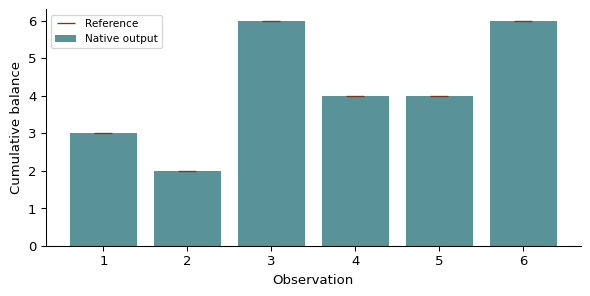

In [3]:
labels = [str(v) for v in range(1, 7)]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Observation", ylabel="Cumulative balance")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

A flat section corresponds to a zero change. The final balance must equal the sum of the full input even when earlier balances fall.

## Exercise

Insert a negative change at the start. Verify both the prefix values and the final-sum property.

## References

[The Rust Programming Language](https://doc.rust-lang.org/book/)